# Phase 2 – Unsupervised Learning
## CCO Retail Intelligence and Customer Retention Advisory System

This notebook applies Gaussian Mixture Model (GMM) to group customers based on their purchasing and engagement behavior. GMM is our second clustering algorithm alongside K-Means.

We prepare the data, choose the number of clusters, evaluate GMM, describe the customer groups, and discuss how the results could support the CCO system.


In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Look for the dataset in the usual project locations
CANDIDATES = ["../Dataset/retail_customer_churn.csv",
              "Dataset/retail_customer_churn.csv",
              "retail_customer_churn.csv"]
DATA_PATH = os.environ.get("CHURN_DATA") or next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()

Loaded: ../Dataset/retail_customer_churn.csv
Shape: (100000, 18)


,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


## 1. Clustering Rationale & Algorithm Selection

### 1.1 Dataset Inspection

We checked the feature types, missing values, distributions, and correlations to understand the data before clustering.


In [3]:
ID_AND_TARGETS = ["customer_id", "churn_flag", "churn_risk"]   # exclude from clustering
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in ID_AND_TARGETS]
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in ID_AND_TARGETS]
print("Numerical features  :", num_cols)
print("Categorical features:", cat_cols)
print("Missing values      :", int(df.isna().sum().sum()))
print("Duplicate rows      :", int(df.duplicated().sum()))

Numerical features  : ['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']
Categorical features: ['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel']
Missing values      : 0
Duplicate rows      : 0


In [4]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
purchase_frequency,100000.0,11.80,14.37,1.00,2.00,8.00,12.00,60.00
avg_order_value,100000.0,209.70,109.71,20.03,114.61,209.48,304.75,400.00
total_spent,100000.0,2543.89,3790.84,17.87,381.32,1089.18,2952.17,28444.24
recency_days,100000.0,182.74,105.12,1.00,92.00,182.00,274.00,364.00
website_visits,100000.0,58.52,78.80,2.00,10.00,29.00,71.00,479.00
discount_usage_rate,100000.0,0.43,0.22,0.05,0.24,0.43,0.61,0.80
email_open_rate,100000.0,0.47,0.25,0.05,0.26,0.47,0.69,0.90
cart_abandonment_rate,100000.0,0.45,0.23,0.05,0.25,0.45,0.65,0.85
loyalty_score,100000.0,54.62,25.96,10.00,32.00,55.00,77.00,99.00
engagement_score,100000.0,51.18,16.83,10.00,39.00,51.00,63.00,92.00


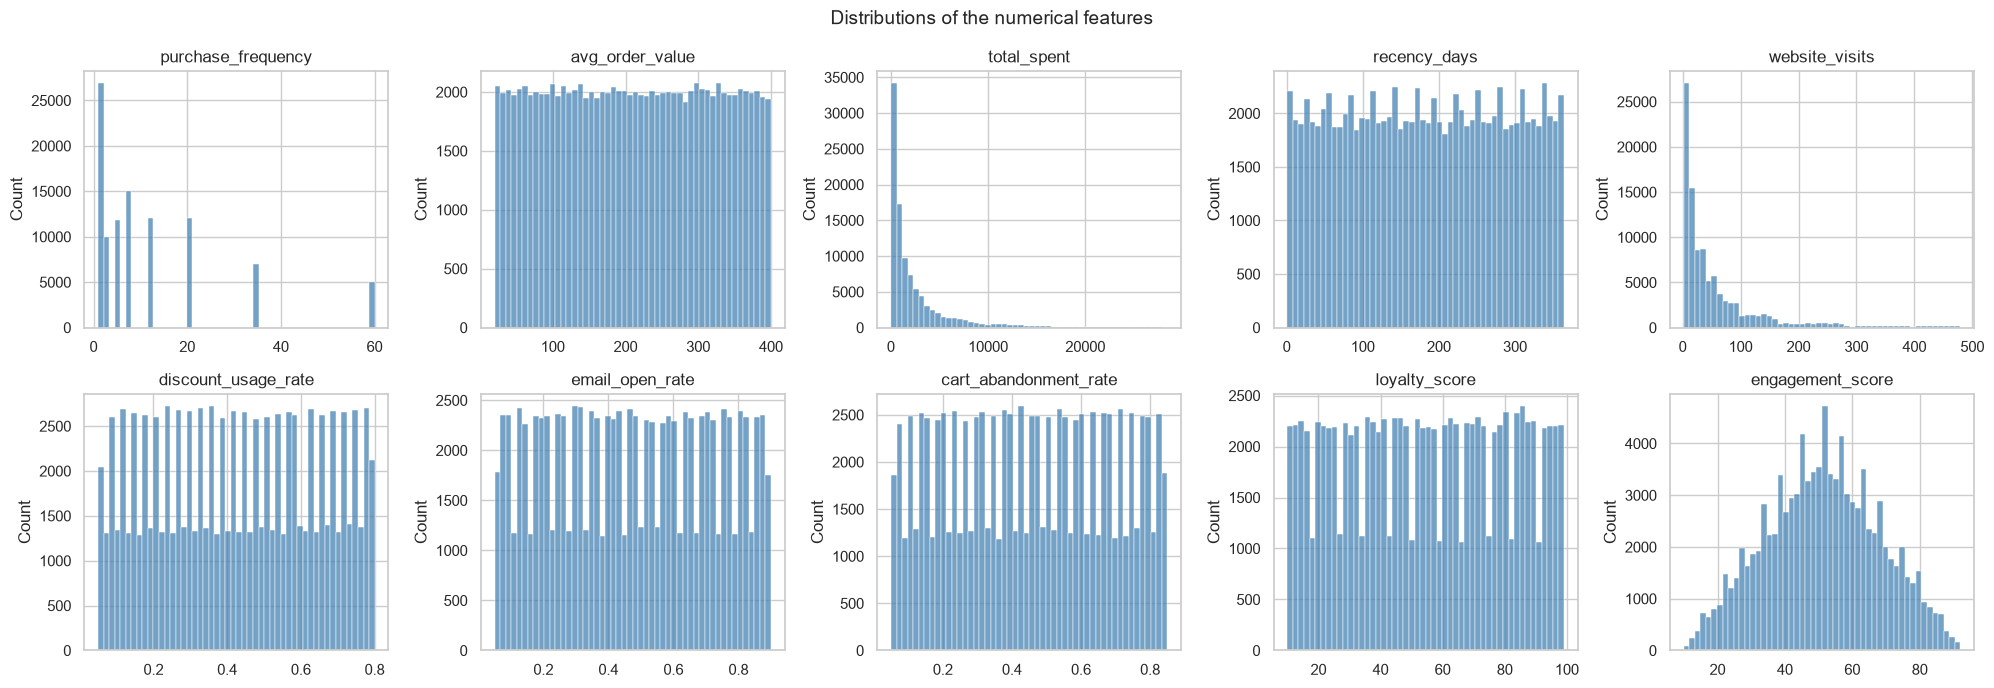

,n_unique,skewness
purchase_frequency,9,2.07
avg_order_value,35250,0.00
total_spent,86590,2.99
recency_days,364,-0.00
website_visits,478,2.59
discount_usage_rate,76,-0.00
email_open_rate,86,0.00
cart_abandonment_rate,81,-0.00
loyalty_score,90,-0.01
engagement_score,165,0.00


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=50, ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Distributions of the numerical features", fontsize=14)
plt.tight_layout(); plt.show()

# Check unique values and skewness
pd.DataFrame({"n_unique": df[num_cols].nunique(), "skewness": df[num_cols].skew().round(2)})

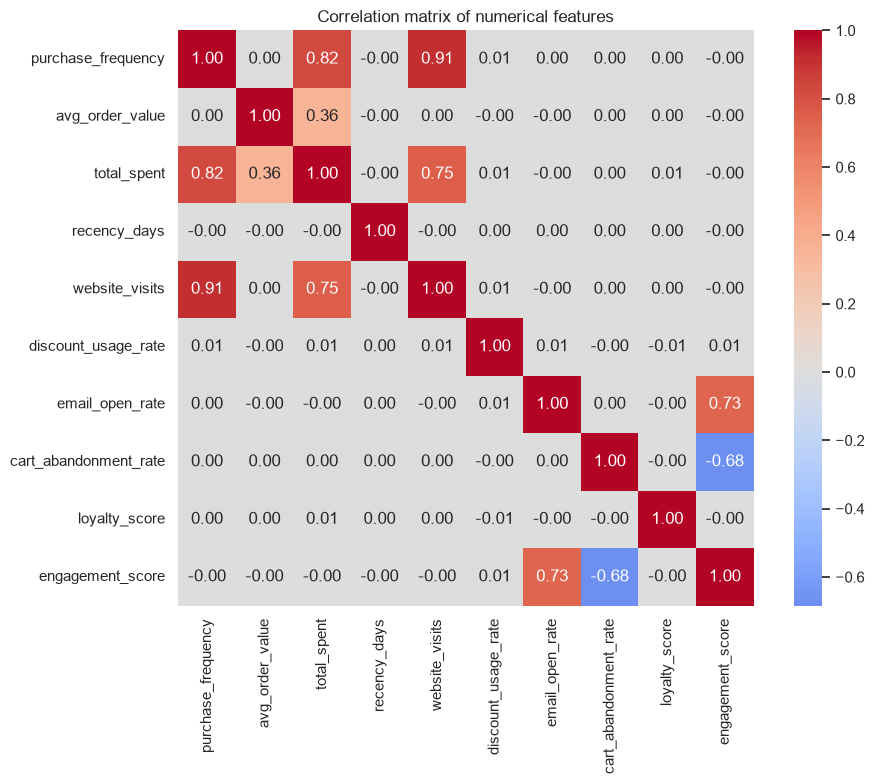

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix of numerical features")
plt.tight_layout(); plt.show()

### 1.2 Algorithm Selection and Justification

We selected GMM as our second clustering algorithm to compare with K-Means. Our dataset contains 100,000 customers, with 10 numerical and 5 categorical features after excluding the ID and churn-related columns.

The plots show that purchase frequency, total spending, and website visits are right-skewed. Some purchasing features are strongly correlated; for example, purchase frequency and website visits have a correlation of 0.91.

GMM provides probabilities of belonging to each cluster. With full covariance, it can also account for relationships between numerical features within each group. This makes it useful for comparison with K-Means, which assigns each customer to one cluster based on distance.

We also considered K-Prototypes because the dataset has categorical features, and DBSCAN because it can find clusters with different shapes. However, K-Prototypes requires choices about how to balance categorical and numerical features, while DBSCAN requires suitable density parameters.

GMM has limitations. Some of our features are skewed or discrete, and the results may depend on how the model is initialized. We evaluate the results before deciding whether the clusters are meaningful.


## 2. Data Preparation

We excluded `customer_id`, `churn_flag`, and `churn_risk` from the clustering inputs. We used the 10 numerical features and applied `StandardScaler` because the feature ranges are very different.

The dataset has no missing values, so imputation was not needed. We excluded categorical features from the main GMM model because they are not directly suited to Gaussian modeling.

In [7]:
from sklearn.pipeline import Pipeline

FEATURES = num_cols
preprocess = Pipeline([
    ("scale", StandardScaler()),
])
X = preprocess.fit_transform(df[FEATURES])
print("Clustering matrix:", X.shape)
print("Means ≈ 0:", np.allclose(X.mean(0), 0, atol=1e-8), "| Std ≈ 1:", np.allclose(X.std(0), 1, atol=1e-8))

Clustering matrix: (100000, 10)
Means ≈ 0: True | Std ≈ 1: True


### 2.1 Categorical Feature Selection

We used numerical features for GMM because one-hot encoded categorical values do not fit its Gaussian assumptions as naturally. We also checked whether average purchasing and engagement behavior differed much across the categorical groups.


In [8]:
# Compare average customer activity across categories
check = []
for c in cat_cols:
    g = df.groupby(c)[["purchase_frequency", "total_spent", "loyalty_score", "engagement_score"]].mean()
    check.append((g.max() - g.min()).rename(c))
print("Range of category means (max - min) per feature:")
display(pd.DataFrame(check).round(2))
print("Overall std for reference:")
display(df[["purchase_frequency", "total_spent", "loyalty_score", "engagement_score"]].std().round(2).to_frame().T)

Range of category means (max - min) per feature:


,purchase_frequency,total_spent,loyalty_score,engagement_score
age_group,0.25,54.83,0.33,0.33
gender,0.17,49.02,0.16,0.16
region,0.37,108.14,0.36,0.35
customer_segment,0.05,22.76,0.32,0.31
preferred_channel,0.19,43.33,0.46,0.05


Overall std for reference:


,purchase_frequency,total_spent,loyalty_score,engagement_score
0,14.37,3790.84,25.96,16.83


The differences between category averages are small compared with the overall variation in the data. For example, average spending varies by 108.14 between regions, while its overall standard deviation is 3,790.84.

This only compares averages for selected features, so it does not prove that categorical features have no useful information. We used the 10 numerical features for the main GMM experiment.

## 3. Cluster Determination & Implementation

### 3.1 Selecting the Number of Clusters

We tested `k=2` to `k=12` using full-covariance GMM. We compared BIC, AIC, Silhouette Score, Davies-Bouldin Index, WCSS, cluster sizes, and stability across three random seeds.

We fitted the models on all 100,000 customers. We calculated Silhouette on a fixed sample of 10,000 customers to reduce computation. WCSS is based on the final cluster labels; it is not the objective that GMM optimizes.


In [9]:
def wcss(X, labels):
    return float(sum(((X[labels == c] - X[labels == c].mean(0)) ** 2).sum() for c in np.unique(labels)))

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X), 10_000, replace=False)   # same sample for each k
X_sample = X[sample_idx]

SEEDS = [0, 1, 2]
rows = []
t0 = time.time()
for k in range(2, 13):
    labels, models = [], []
    for s in SEEDS:
        g = GaussianMixture(n_components=k, covariance_type="full", n_init=1,
                            max_iter=300, random_state=s).fit(X)
        models.append(g); labels.append(g.predict(X))
    g, L = models[0], labels[0]
    sizes = np.bincount(L, minlength=k) / len(L) * 100
    ari = np.mean([adjusted_rand_score(labels[i], labels[j]) for i in range(3) for j in range(i + 1, 3)])
    rows.append({"k": k, "BIC": g.bic(X), "AIC": g.aic(X),
                 "Silhouette_10k": silhouette_score(X_sample, L[sample_idx]),
                 "DaviesBouldin": davies_bouldin_score(X, L),
                 "WCSS": wcss(X, L),
                 "min_cluster_%": sizes.min(), "max_cluster_%": sizes.max(),
                 "stability_ARI": ari, "converged": g.converged_})
results = pd.DataFrame(rows).set_index("k")
print(f"Search took {time.time() - t0:.0f}s")
results.round(3)

Search took 290s


,BIC,AIC,Silhouette_10k,DaviesBouldin,WCSS,min_cluster_%,max_cluster_%,stability_ARI,converged
k,,,,,,,,,
2,652060.336,650814.143,0.151,2.380,863010.957,33.982,66.018,1.000,True
3,453679.758,451805.712,0.018,5.787,825404.236,24.879,38.677,0.999,True
4,283963.820,281461.921,0.008,18.557,825025.072,14.813,38.270,1.000,True
5,139195.319,136065.567,0.003,18.888,820800.647,11.888,26.976,1.000,True
6,146146.542,142388.936,0.012,4.264,735322.436,5.008,30.985,0.580,True
7,123727.487,119342.029,0.007,4.304,719211.466,5.008,22.935,0.609,True
8,4753.219,-260.093,0.008,19.644,731889.670,9.988,15.161,0.654,True
9,-255265.909,-260907.074,-0.007,11.501,718228.484,5.008,22.100,0.587,True
10,-5541.785,-11810.802,-0.041,16.067,733243.756,0.010,14.813,0.626,True


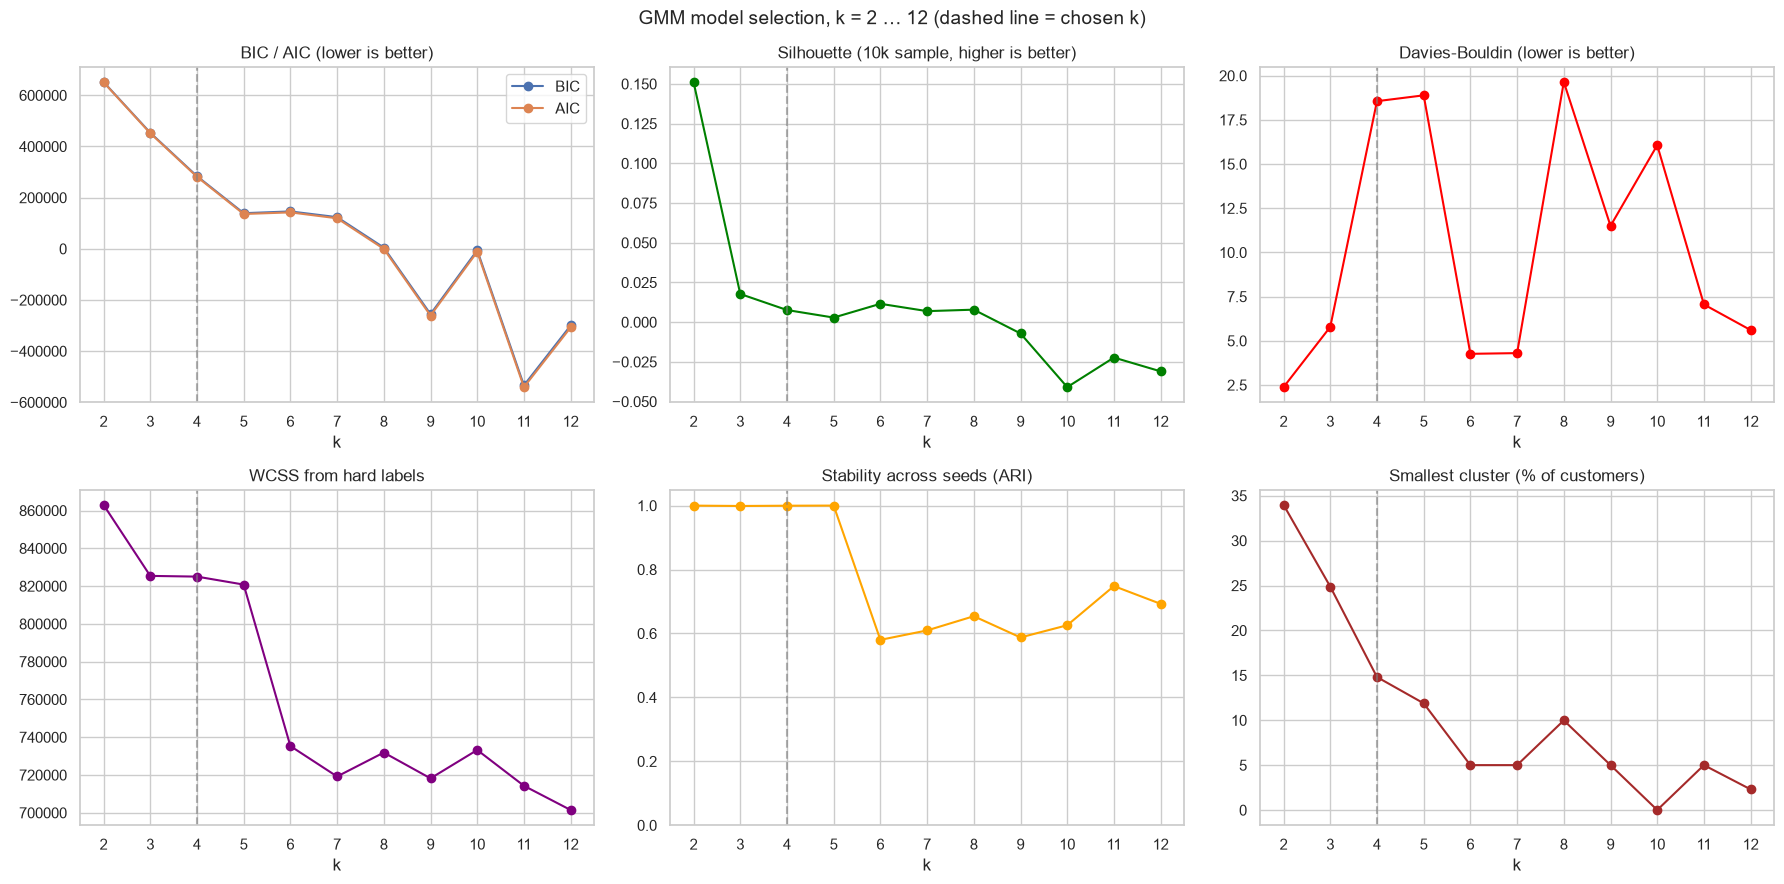

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
results[["BIC", "AIC"]].plot(ax=axes[0, 0], marker="o"); axes[0, 0].set_title("BIC / AIC (lower is better)")
results["Silhouette_10k"].plot(ax=axes[0, 1], marker="o", color="green"); axes[0, 1].set_title("Silhouette (10k sample, higher is better)")
results["DaviesBouldin"].plot(ax=axes[0, 2], marker="o", color="red"); axes[0, 2].set_title("Davies-Bouldin (lower is better)")
results["WCSS"].plot(ax=axes[1, 0], marker="o", color="purple"); axes[1, 0].set_title("WCSS from hard labels")
results["stability_ARI"].plot(ax=axes[1, 1], marker="o", color="orange"); axes[1, 1].set_title("Stability across seeds (ARI)"); axes[1, 1].set_ylim(0, 1.05)
results["min_cluster_%"].plot(ax=axes[1, 2], marker="o", color="brown"); axes[1, 2].set_title("Smallest cluster (% of customers)")
for ax in axes.ravel():
    ax.axvline(4, ls="--", color="grey", alpha=.6); ax.set_xticks(range(2, 13))
plt.suptitle("GMM model selection, k = 2 … 12 (dashed line = chosen k)", fontsize=14)
plt.tight_layout(); plt.show()

### 3.2 Model Selection Results

Silhouette and Davies-Bouldin are best at `k=2` (0.151 and 2.38). At `k=4`, these scores are much weaker (about 0.008 and 18.56), so the four groups are not clearly separated.

BIC and AIC are lower for several larger models, but the scores fluctuate sharply after `k=6`. Our data includes discrete and skewed features, which may encourage GMM to fit narrow components to repeated values. We therefore did not select the number of clusters using BIC alone.

In [11]:
for k in [4, 5]:
    g = GaussianMixture(k, covariance_type="full", random_state=0).fit(X)
    L = g.predict(X)
    summary = df.groupby(L)["purchase_frequency"].agg(["mean", "min", "max", "nunique", "size"]).sort_values("mean")
    print(f"k = {k}"); display(summary)

k = 4


,mean,min,max,nunique,size
1,1.000000,1,1,1,14813
2,2.450728,2,3,2,22051
0,8.239012,3,12,4,38270
3,32.014035,12,60,4,24866


k = 5


,mean,min,max,nunique,size
1,1.000000,1,1,1,14813
0,2.451946,2,3,2,22100
2,5.000000,5,5,1,11888
4,9.765569,8,12,2,26976
3,32.545308,12,60,4,24223


### 3.3 Choosing the Number of Clusters

We selected **k=4** as a practical way to describe different levels of purchasing activity. At `k=2`, the distance-based evaluation scores are better, but the model mainly divides customers into lower- and higher-activity groups.

Although `k=5` has a lower BIC than `k=4`, the extra group in the table above contains only customers with exactly five purchases. We did not treat this as a separate customer type because it appears to reflect the discrete purchase-frequency values.

The first three seeds gave similar results for `k=4`, but we checked more seeds in the final training step. This choice prioritizes interpretable groups and is not the best result for every metric.

### 3.4 Training the Final GMM

We fitted GMM with `n_components=4` and `covariance_type="full"`, so each group can have its own covariance matrix. We used `max_iter=300` and the default covariance regularization (`reg_covar=1e-6`).

We ran the model with ten random seeds (`n_init=1` per run, using the default k-means initialization) and kept the run with the lowest BIC. We then renamed the groups from lowest to highest average purchase frequency to make the profiles easier to read.

In [12]:
# Try different starting points and keep the model with the lowest BIC.
t0 = time.time()
fits = {s: GaussianMixture(n_components=4, covariance_type="full", n_init=1,
                           max_iter=300, random_state=s).fit(X) for s in range(10)}
best_seed = min(fits, key=lambda s: fits[s].bic(X))
gmm = fits[best_seed]
best_labels = gmm.predict(X)
seed_table = pd.DataFrame({
    "BIC": {s: g.bic(X) for s, g in fits.items()},
    "ARI_vs_best": {s: adjusted_rand_score(best_labels, g.predict(X)) for s, g in fits.items()},
    "smallest_cluster_%": {s: np.bincount(g.predict(X)).min() / len(X) * 100 for s, g in fits.items()},
}).rename_axis("seed")
print(f"10 fits took {time.time() - t0:.0f}s | best seed: {best_seed} | converged: {gmm.converged_} | EM iterations: {gmm.n_iter_}")
print(f"Seeds that reach the best solution (ARI > 0.99): {(seed_table['ARI_vs_best'] > 0.99).sum()} / 10")
display(seed_table.round(3))

raw_labels = best_labels
proba = gmm.predict_proba(X)

# Order cluster IDs by average purchase frequency
order = df.groupby(raw_labels)["purchase_frequency"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
df["cluster"] = pd.Series(raw_labels).map(remap).values
proba = proba[:, list(order)]
df["cluster_confidence"] = proba.max(1)

PERSONAS = {0: "One-time Buyers", 1: "Occasional Buyers", 2: "Regular Buyers", 3: "Heavy Users"}
df["persona"] = df["cluster"].map(PERSONAS)
df[["customer_id", "cluster", "persona", "cluster_confidence"]].head()

10 fits took 52s | best seed: 2 | converged: True | EM iterations: 36
Seeds that reach the best solution (ARI > 0.99): 3 / 10


,BIC,ARI_vs_best,smallest_cluster_%
seed,,,
0,283963.820,0.999,14.813
1,283963.825,0.999,14.813
2,283962.733,1.000,14.813
3,396125.907,0.612,20.186
4,448652.971,0.820,16.913
5,384985.841,0.511,12.176
6,403132.740,0.563,19.420
7,395839.912,0.611,21.016
8,396137.245,0.612,20.152


,customer_id,cluster,persona,cluster_confidence
0,C000001,2,Regular Buyers,0.999503
1,C000002,2,Regular Buyers,0.998669
2,C000003,2,Regular Buyers,0.999738
3,C000004,2,Regular Buyers,0.904941
4,C000005,1,Occasional Buyers,0.997363


### Initialization Results

Only 3 of the 10 random seeds reached solutions close to the best one. The other runs had higher BIC scores and different customer assignments. This shows that the result depends on initialization, so we used the lowest-BIC run for the final profiles.

## 4. Evaluation Metrics & Visualizations

### 4.1 GMM Evaluation


In [13]:
labels = df["cluster"].values
gmm_metrics = {
    "Silhouette (10k sample)": silhouette_score(X_sample, labels[sample_idx]),
    "Davies-Bouldin (full 100k)": davies_bouldin_score(X, labels),
    "WCSS (full 100k)": wcss(X, labels),
    "BIC (full 100k)": gmm.bic(X),
    "AIC (full 100k)": gmm.aic(X),
    "Avg log-likelihood per sample (full)": gmm.score(X),
    "Mean assignment confidence (full)": df["cluster_confidence"].mean(),
}
pd.Series(gmm_metrics).round(4).to_frame("GMM, k=4")

,"GMM, k=4"
Silhouette (10k sample),0.0077
Davies-Bouldin (full 100k),18.5614
WCSS (full 100k),824977.6482
BIC (full 100k),283962.7327
AIC (full 100k),281460.8333
Avg log-likelihood per sample (full),-1.4047
Mean assignment confidence (full),0.9908


### 4.2 GMM Visualizations

We visualize the group sizes, PCA projection, and cluster membership confidence.


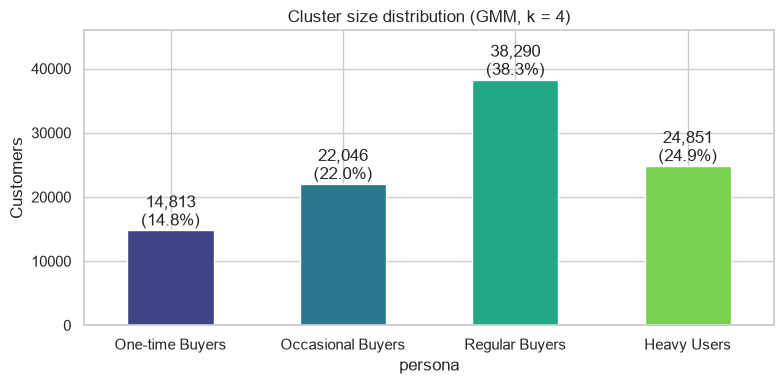

In [14]:
counts = df["persona"].value_counts().reindex(PERSONAS.values())
ax = counts.plot.bar(color=sns.color_palette("viridis", 4), rot=0, figsize=(8, 4))
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Customers"); ax.set_title("Cluster size distribution (GMM, k = 4)")
ax.set_ylim(0, counts.max() * 1.2); plt.tight_layout(); plt.show()

Explained variance ratio: [0.268 0.2  ] | total: 0.468


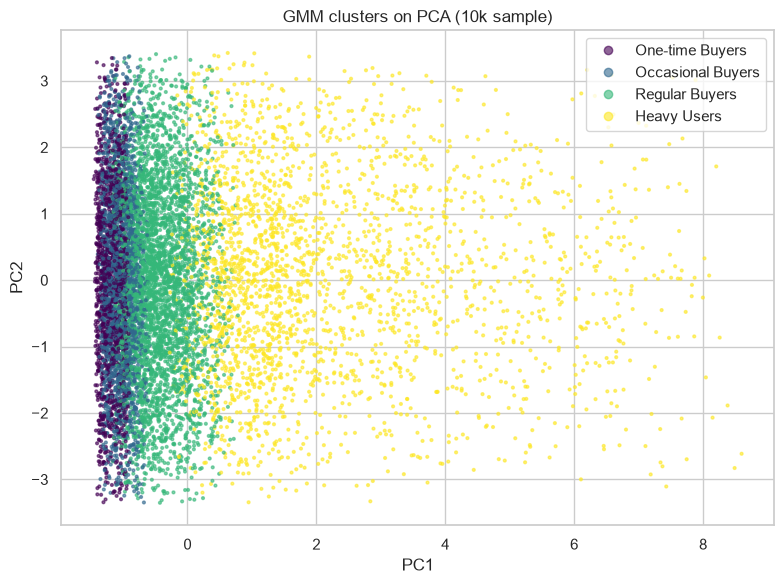

,PC1,PC2
purchase_frequency,0.58,0.00
avg_order_value,0.12,-0.00
total_spent,0.57,0.00
recency_days,-0.00,-0.00
website_visits,0.57,0.00
discount_usage_rate,0.01,0.01
email_open_rate,-0.00,0.52
cart_abandonment_rate,0.00,-0.48
loyalty_score,0.01,-0.00
engagement_score,-0.00,0.71


In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plot_idx = sample_idx
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[plot_idx, 0], X_pca[plot_idx, 1],
                 c=labels[plot_idx], cmap="viridis", s=4, alpha=0.6)
plt.title("GMM clusters on PCA (10k sample)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(handles=sc.legend_elements()[0], labels=list(PERSONAS.values()), loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2)

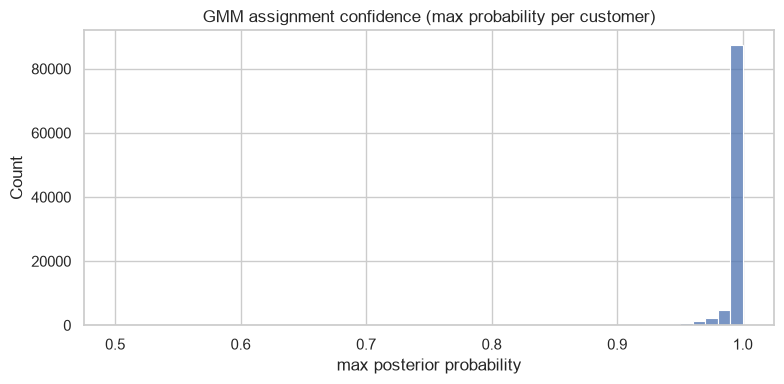

Customers with confidence < 0.8: 1.08%


In [16]:
plt.figure(figsize=(8, 4))
sns.histplot(df["cluster_confidence"], bins=50)
plt.title("GMM assignment confidence (max probability per customer)")
plt.xlabel("max posterior probability"); plt.tight_layout(); plt.show()
print("Customers with confidence < 0.8:", f"{(df['cluster_confidence'] < 0.8).mean():.2%}")


### 4.3 Visualization Findings

The first two principal components explain about 47% of the total variance (26.8% and 20.0%), so the PCA plot only shows part of the variation in the data.

The clusters are mainly arranged along PC1, which is related to purchasing activity, including purchase frequency, total spending, and website visits. The groups overlap, especially among the lower-activity segments. PC2 does not clearly separate them.

The Davies-Bouldin score is high (18.56), and the Silhouette Score is close to zero. These results indicate weak distance-based separation, even though GMM assigns high membership probabilities to many customers.


### 4.4 Comparison with K-Means

## 5. Cluster Interpretation & Profiles

We used the original feature values to describe the customer groups. The group names reflect purchasing activity, not churn risk.


In [17]:
KEY = ["purchase_frequency", "avg_order_value", "total_spent", "recency_days", "website_visits",
       "discount_usage_rate", "loyalty_score", "engagement_score"]
profile = df.groupby("persona")[FEATURES].mean().reindex(PERSONAS.values())
profile["size_%"] = df["persona"].value_counts(normalize=True).reindex(PERSONAS.values()) * 100
profile.T.round(2)

persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
purchase_frequency,1.00,2.45,8.24,32.03
avg_order_value,209.49,210.08,205.98,215.24
total_spent,215.09,527.54,1714.19,6999.17
recency_days,183.91,182.80,182.37,182.56
website_visits,4.49,11.73,40.74,159.64
discount_usage_rate,0.43,0.43,0.43,0.43
email_open_rate,0.48,0.47,0.47,0.48
cart_abandonment_rate,0.45,0.45,0.45,0.45
loyalty_score,54.77,54.40,54.58,54.77
engagement_score,51.02,51.17,51.17,51.28


In [18]:
# Medians of the key features (less affected by the long tails than the means)
df.groupby("persona")[KEY].median().reindex(PERSONAS.values()).T.round(2)

persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
purchase_frequency,1.00,2.00,8.00,20.00
avg_order_value,208.78,209.45,204.97,217.41
total_spent,212.34,500.33,1527.23,5645.53
recency_days,184.00,183.00,182.00,182.00
website_visits,4.00,11.00,36.00,132.00
discount_usage_rate,0.43,0.42,0.42,0.43
loyalty_score,55.00,54.00,55.00,55.00
engagement_score,51.00,51.00,51.00,51.50


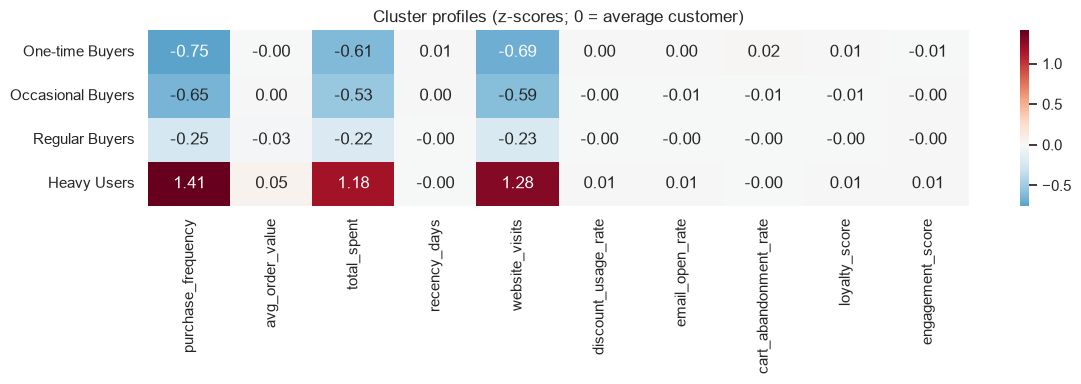

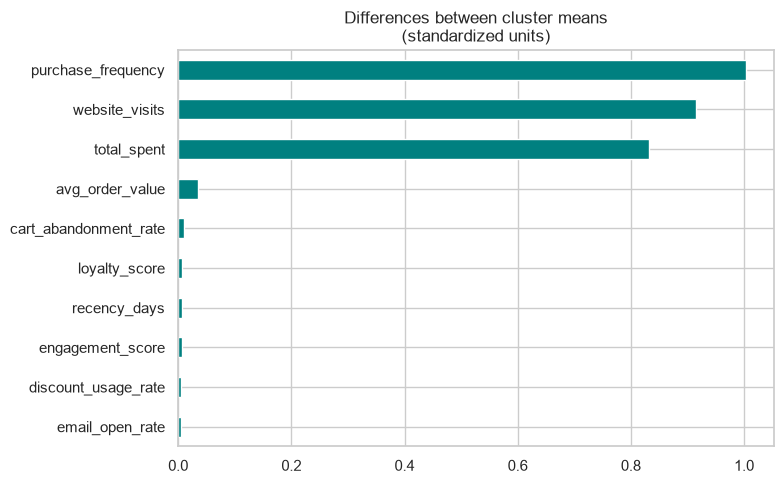

In [19]:
# Feature profile heatmap: cluster mean in standard deviations from the overall mean
z_profile = pd.DataFrame(X, columns=FEATURES).groupby(labels).mean()
z_profile.index = [PERSONAS[i] for i in z_profile.index]
plt.figure(figsize=(12, 4))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-scores; 0 = average customer)"); plt.tight_layout(); plt.show()

# Compare differences in cluster means across features
importance = z_profile.std().sort_values(ascending=True)
importance.plot.barh(figsize=(8, 5), color="teal")
plt.title("Differences between cluster means\n(standardized units)")
plt.tight_layout(); plt.show()

In [20]:
# Churn per cluster (churn was NOT used for clustering; we only check it afterwards)
churn_tab = df.groupby("persona").agg(customers=("customer_id", "size"),
                                      churn_rate=("churn_flag", "mean")).reindex(PERSONAS.values())
churn_tab = churn_tab.join(pd.crosstab(df["persona"], df["churn_risk"], normalize="index"))
display(churn_tab.round(3))
print("Overall churn rate:", round(df["churn_flag"].mean(), 3))

,customers,churn_rate,High,Low,Medium
persona,,,,,
One-time Buyers,14813,0.486,0.346,0.378,0.276
Occasional Buyers,22046,0.478,0.343,0.383,0.274
Regular Buyers,38290,0.468,0.328,0.397,0.275
Heavy Users,24851,0.426,0.288,0.438,0.274


Overall churn rate: 0.462


### 5.1 Customer Segments
The main differences between the groups are purchase frequency, website visits, and total spending. We named them according to purchasing activity:

| Cluster | Segment | Main characteristics |
|---|---|---|
| 0 | One-time Buyers | Around 15% of customers; one purchase and about 215 in total spending |
| 1 | Occasional Buyers | Around 22%; usually 2–3 purchases and about 530 in spending |
| 2 | Regular Buyers | Around 38%; about 8 purchases and 1,700 in spending |
| 3 | Heavy Users | Around 25%; about 32 purchases and 7,000 in spending |

Average order value is similar across the groups, so spending differences mostly follow purchase frequency. Recency, discount usage, loyalty score, and engagement score are also similar across all four groups. We therefore did not describe any group as more loyal or more engaged.

Churn rates range from about 42.6% to 48.6%. These clusters are not churn predictions; that task belongs to Phase 1.

### 5.2 Added Value of GMM

The clusters are mainly related to purchase frequency, so simple rules could produce similar customer groups. We checked whether GMM adds anything beyond such rules by looking at customers with the same purchase count in different clusters, and at customers with lower assignment confidence.

In [26]:
# Find purchase counts that appear in more than one cluster
groups_per_value = df.groupby("purchase_frequency")["persona"].nunique()
shared_values = groups_per_value[groups_per_value > 1].index.tolist()
print("Purchase counts found in more than one cluster:", shared_values)

# Check whether customers with the same purchase count
# can belong to different clusters
boundary = df[df["purchase_frequency"].isin(shared_values)]

display(pd.crosstab(
    boundary["purchase_frequency"],
    boundary["persona"]
))

# Check customers with lower assignment confidence
borderline = df[df["cluster_confidence"] < 0.8]

print("Customers with confidence below 80%:", len(borderline))
print("Percentage:", round(len(borderline) / len(df) * 100, 2), "%")

display(borderline["persona"].value_counts())

Purchase counts found in more than one cluster: [3, 12]


persona,Heavy Users,Occasional Buyers,Regular Buyers
purchase_frequency,,,
3,0,9934,54
12,813,0,11279


Customers with confidence below 80%: 1076
Percentage: 1.08 %


persona
Regular Buyers       555
Heavy Users          345
Occasional Buyers    176
Name: count, dtype: int64


The results show that customers with the same purchase frequency can belong to different clusters. This happened at purchase frequencies of 3 and 12. For example, among customers with 12 purchases, 11,279 were classified as Regular Buyers and 813 as Heavy Users. This shows that purchase frequency alone does not fully determine the cluster assignments.

GMM also provides membership probabilities. We found that 1,076 customers (1.08%) had an assignment confidence below 80%. Most of these customers were Regular Buyers (555), followed by Heavy Users (345) and Occasional Buyers (176).

These probabilities could help the CCO system identify customers whose cluster assignments are less certain.


## 6. Integration Strategy

The supervised model from Phase 1 predicts churn risk, while GMM groups customers by purchasing activity. The CCO system could combine these results to suggest retention actions.

For example, One-time Buyers could receive a second-purchase offer, while Occasional Buyers could receive a reminder or recommendation based on their recent purchases. Regular Buyers could receive personalized product suggestions, and Heavy Users could be offered priority support or a reward. Churn predictions from Phase 1 could help decide which customers to prioritize. These are proposed actions, not strategies tested in this experiment.

The notebook exports customer IDs, group labels, and membership probabilities. 
The notebook exports the customer segmentation results as a CSV file. We also saved the trained GMM model and preprocessing pipeline so that new customers can be assigned to the same segments.


In [22]:
os.makedirs("outputs", exist_ok=True)
out = df[["customer_id", "cluster", "persona", "cluster_confidence"]].join(
    pd.DataFrame(proba, columns=[f"p_{PERSONAS[i].replace(' ', '_')}" for i in range(4)]))
out.to_csv("outputs/gmm_customer_segments.csv", index=False)
print("Saved", out.shape, "-> outputs/gmm_customer_segments.csv")
out.head()

Saved (100000, 8) -> outputs/gmm_customer_segments.csv


,customer_id,cluster,persona,cluster_confidence,p_One-time_Buyers,p_Occasional_Buyers,p_Regular_Buyers,p_Heavy_Users
0,C000001,2,Regular Buyers,0.999503,0.0,1.896934e-17,0.999503,0.000497
1,C000002,2,Regular Buyers,0.998669,0.0,1.095634e-106,0.998669,0.001331
2,C000003,2,Regular Buyers,0.999738,0.0,1.159450e-09,0.999738,0.000262
3,C000004,2,Regular Buyers,0.904941,0.0,8.861857e-101,0.904941,0.095059
4,C000005,1,Occasional Buyers,0.997363,0.0,9.973633e-01,0.002593,0.000043



### 6.1 Saving and Reusing the GMM Model

We saved the trained GMM model and preprocessing pipeline so that new customers can be assigned to the same segments without retraining the model.

We also saved the feature names and cluster mapping to keep the assignments consistent.


In [27]:
import joblib

# Save everything needed to assign new customers to the same segments
model_bundle = {
    "preprocess": preprocess,   # fitted StandardScaler pipeline
    "gmm": gmm,                 # fitted GMM model
    "order": list(order),       # original GMM cluster IDs, ordered by purchase frequency
    "personas": PERSONAS,       # cluster number -> segment name
    "features": FEATURES,       # input columns in the correct order
}
joblib.dump(model_bundle, "outputs/gmm_model.joblib")
print("Saved -> outputs/gmm_model.joblib")

Saved -> outputs/gmm_model.joblib


In [29]:

# Load the saved model
bundle = joblib.load("outputs/gmm_model.joblib")

def assign_segment(customers):
    X_new = bundle["preprocess"].transform(
        customers[bundle["features"]]
    )

    probabilities = bundle["gmm"].predict_proba(X_new)
    probabilities = probabilities[:, bundle["order"]]

    clusters = probabilities.argmax(axis=1)

    return pd.DataFrame({
        "cluster": clusters,
        "persona": [bundle["personas"][c] for c in clusters],
        "cluster_confidence": probabilities.max(axis=1)
    }, index=customers.index)


# Check that the saved model reproduces the existing assignments
check = assign_segment(df)

print(
    "Same segments as before:",
    (check["cluster"].values == df["cluster"].values).all()
)


Same segments as before: True


In [30]:

# Example of a new customer
new_customer = pd.DataFrame([{
    "purchase_frequency": 15,
    "avg_order_value": 200,
    "total_spent": 3000,
    "recency_days": 30,
    "website_visits": 80,
    "discount_usage_rate": 0.3,
    "email_open_rate": 0.5,
    "cart_abandonment_rate": 0.2,
    "loyalty_score": 70,
    "engagement_score": 60
}])

display(assign_segment(new_customer))


,cluster,persona,cluster_confidence
0,2,Regular Buyers,0.945245



The example customer made 15 purchases and was classified as a Regular Buyer with 94.5% confidence.

Although this is a hypothetical customer, the example shows how the saved GMM model can be used to assign new customers to existing segments. The model considers all 10 numerical features when making the assignment, rather than using purchase frequency alone.


## 7. Challenges & Limitations

**Weak cluster separation.** The Silhouette Score for `k=4` is close to zero, and Davies-Bouldin is high (18.56). The groups mainly describe levels of purchasing activity rather than clearly separated customer types.

**Feature distributions.** Some inputs are skewed or discrete, which may not fit Gaussian components well. Correlated purchasing features may also have more influence on the grouping.

**Initialization.** Only 3 of the 10 seeds reached solutions close to the lowest-BIC result, so we kept the best run.

**Feature selection and scaling.** We excluded categorical features, and different feature sets or scaling methods could produce different clusters.

**Limited churn differences.** Churn rates are fairly similar across the four groups. GMM should support segmentation, not replace the Phase 1 churn model.

**Computational cost.** Fitting GMM on 100,000 customers takes time, so we calculated Silhouette using a 10,000-customer sample.

Future work could test transformations for skewed features and evaluate whether the groups help improve retention decisions.